# 3.4 시장지수 내 대형주 기여분에 대한 민감도 분석

**질문:** 삼성전자·SK하이닉스가 각각 자기 기여분을 근사 제외한 시장을 사용하면 기대 수익률, 가격 Z와 경보 날짜가 얼마나 달라지는가? 기본 모델은 지수 원값을 사용하며, 이 실험은 자기 포함 영향의 크기를 점검한다.

| 비교 | 삼성전자 회귀 입력 | SK하이닉스 회귀 입력 | 다른 4개 기업 |
|---|---|---|---|
| `BASE` | 원 KOSPI | 원 KOSPI | 원 시장지수 |
| `EX_SAMSUNG` | 삼성전자 자기 몫 근사 제외 시장 | 원 KOSPI | 원 시장지수 |
| `EX_HYNIX` | 원 KOSPI | SK하이닉스 자기 몫 근사 제외 시장 | 원 시장지수 |
| `SELF_EXCLUDED` | 삼성전자 자기 몫 근사 제외 시장 | SK하이닉스 자기 몫 근사 제외 시장 | 원 시장지수 |

현재 프로젝트의 **`build_panel()`·`core.detect()`를 그대로 사용**한다. `run_config.json`의 분석 기간·120/40 구간·가격/거래량 2.5·시장 120/3.0 설정과 입력 해시를 확인한다. 기존 종목 가격·거래량, 35개 peer, 자기 제외, 결측·30% 초과 필터는 유지한다. 2024년 준비 자료부터 조정하여 **순섹터 생성 → 종목 회귀 → 과거 잔차 → 가격 Z → 경보**를 대상 종목별로 다시 계산한다. 조정 시장 Z도 해당 종목별로 계산하며 원 지수의 시장 Z와 구분한다. `SELF_EXCLUDED`는 두 종목 몫을 함께 뺀 하나의 지수를 뜻하지 않는다.

**추가 자료와 해석 범위**

기존 `stocks.csv`·`markets.csv`에는 지수 비중이 없다. 셀 2에서 KRX 일별 시가총액을 `pykrx`로 수집·보관한다. 시가총액 비중으로 만든 **자기 몫 근사 제외 시장**이며 공식 제외 지수를 재현하지 않는다. 지수용 주식 수·구성·제수 및 기업행사 조정을 완전히 재현하지 않는다. 삼성전자의 자기 몫은 분석 대상인 보통주(005930) 기준이다. 기사에 제시된 두 회사의 합계 비중이나 지수 상승 기여율·거래대금 비중으로 일별 비중을 대체하지 않는다.

$$w_{i,t-1}=\frac{\mathrm{Cap}_{i,t-1}}{\mathrm{Cap}_{KOSPI,t-1}},\qquad
r^{ex(i)}_{M,t}=\frac{r_{M,t}-w_{i,t-1}r_{i,t}}{1-w_{i,t-1}}$$

종목 수익률은 기존 입력을 사용하고, 비중은 **직전 거래일**의 자료를 사용한다. 기여분을 차감한 뒤 남은 비중으로 나누어 재가중한다. 현재 비중을 과거 전체에 적용하거나 결측 비중을 임의로 채우지 않는다. 회귀에는 당일 이전 자료만 사용하며, 당일 종목·시장 수익률은 기존과 동일하게 장 마감 후 평가에 사용한다.

**실행:** 이 노트북을 `FDS_regression_model` 또는 그 안의 `experiments`에 놓고 기존 `aicam` 커널에서 Run All. 다른 위치라면 셀 1의 `MODEL_DIR`을 지정한다. 추가 패키지가 없다면 별도 셀에서 `%pip install -U pykrx matplotlib` 실행 후 커널을 재시작한다. 최초 수집에는 KRX 계정이 필요할 수 있으며, 셀 2의 숨김 입력창에서만 입력한다. 계정 정보는 결과 파일에 저장하지 않는다. 수집 후에는 캐시를 재사용한다.

**주로 볼 셀:** 2(비중·자료 확인), **5(주요 비교표), 6(기업·기간), 7(변경 사례), 8(보고서 그림)**. 셀 9에서 CSV·그림·설정 기록을 실험 전용 폴더에 저장한다. 기존 모델의 CSV·경보 JSON에 합치지 않는다.

## 코드 셀 1 · 현재 실행 조건과 기준 결과 재현
현재 기록은 분석 2025-01-02~2026-10-08, 2,574개 종목·거래일, OR 경보 138건이다. 날짜·설정·건수를 코드에 고정하지 않고 실행 기록에서 읽어 확인한다.

In [7]:
from pathlib import Path
import hashlib, importlib.metadata, json, os, platform, sys
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

MODEL_DIR = None  # 필요하면 Path(r"C:\ai_campus_mini_proj\FDS_regression_model")
CAPS_CSV = None   # 자동 수집 대신 아래 설명의 정규화된 시가총액 CSV를 사용할 때 지정
CAPS_SOURCE = "" # CAPS_CSV를 지정하면 실제 출처·추출 방법도 적을 것
if MODEL_DIR is None:
    choices = [p / name for p in [Path.cwd(), *Path.cwd().parents]
               for name in ("", "FDS_regression_model")]
    MODEL_DIR = next((p for p in choices if (p / "semiconductor_model/core.py").is_file()), None)
if MODEL_DIR is None:
    raise FileNotFoundError("MODEL_DIR에 FDS_regression_model 폴더를 지정하세요.")
MODEL_DIR = Path(MODEL_DIR).resolve()
sys.path.insert(0, str(MODEL_DIR))
from semiconductor_model import core
from semiconductor_model.config import CONFIG
from semiconductor_model.data import read_inputs, build_panel
assert Path(core.__file__).resolve().parents[1] == MODEL_DIR, "커널을 재시작하고 다시 실행하세요."
run = json.loads((MODEL_DIR / "run_config.json").read_text(encoding="utf-8"))
assert CONFIG.to_dict() == run["model"], "설정이 실행 기록과 다릅니다. 기존 모델을 먼저 실행하세요."
START, END = pd.Timestamp(run["analysis_start"]), pd.Timestamp(run["analysis_end"])
DATA, OUT = MODEL_DIR / "data", MODEL_DIR / "experiments" / "3_4_market_sensitivity"
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
input_hashes = {n: sha(DATA / n) for n in ("stocks.csv", "markets.csv", "calendar.csv", "universe.csv")}
assert input_hashes == run["inputs"]["sha256"], "입력이 실행 기록과 다릅니다. 기존 모델을 먼저 실행하세요."
stocks, markets, calendar, universe = read_inputs(DATA, END)
panel = build_panel(stocks, markets, calendar, universe, CONFIG)
sessions = pd.DatetimeIndex(calendar.date.sort_values(), name="date")
def analysis_rows(f):
    return f.loc[f.date.between(START, END)].set_index(["date", "code"]).sort_index()
baseline_full = core.detect(panel, CONFIG)
base = analysis_rows(baseline_full)
assert len(base) == run["rows"], "기준 분석 행 수가 다릅니다."
assert int((base.price_alert | base.volume_alert).sum()) == run["stock_alert_json_count"], "기준 경보 건수가 다릅니다."
display(pd.DataFrame({"항목": ["분석 기간", "회귀 / Z 구간", "가격 / 거래량 임계값", "종목·거래일 / OR 경보", "기준 재현"],
    "값": [f"{START.date()} ~ {END.date()}", f"{CONFIG.train_window} / {CONFIG.z_window}",
           f"{CONFIG.price_threshold} / {CONFIG.volume_threshold}",
           f"{len(base):,} / {int((base.price_alert | base.volume_alert).sum())}", "PASS"]}))

,항목,값
0,분석 기간,2025-01-02 ~ 2026-10-08
1,회귀 / Z 구간,120 / 40
2,가격 / 거래량 임계값,2.5 / 2.5
3,종목·거래일 / OR 경보,"2,574 / 138"
4,기준 재현,PASS


## 코드 셀 2 · 과거 일별 시가총액 수집·비중 확인
준비 기간을 포함한 거래일 전체의 시가총액을 확인한다. 최초 실행은 KOSPI(지수 코드 `1001`)·삼성전자(`005930`)·SK하이닉스(`000660`)를 조회한다. 시가총액은 모두 **원**, 비중은 **0~1** 단위다. KOSPI 200 비중으로 대체하지 않는다.

자동 수집이 불가능하면 `CAPS_CSV`에 직접 준비한 CSV를 지정한다. 필수 열은 `date,kospi_market_cap,samsung_market_cap,hynix_market_cap,kospi_close`이며, `date`는 YYYY-MM-DD, 나머지는 숫자다. `kospi_close`는 같은 KRX 자료의 KOSPI 종가다. `CAPS_SOURCE`에는 출처·추출 방법을 적는다. 단위가 백만원인 다운로드 자료는 **원으로 변환한 뒤** 입력한다. 누락된 날짜·잘못된 단위·공급자 간 KOSPI 종가 차이(0.1포인트 초과)가 있으면 중단한다.

비중 표는 **분석 날짜에 실제 적용한 전일 비중**이다. 수집 실패 시 임의 비중으로 진행하지 않는다.

In [8]:
print("KRX 수집 진단 v2: 원인 예외 표시")
cap_cols = ["kospi_market_cap", "samsung_market_cap", "hynix_market_cap", "kospi_close"]
CACHE = OUT / "inputs"
cache_file = CACHE / f"market_caps_{sessions.min():%Y%m%d}_{sessions.max():%Y%m%d}.csv"
cache_meta = cache_file.with_suffix(".json")
fresh = False
if CAPS_CSV is not None:
    if not CAPS_SOURCE.strip():
        raise ValueError("CAPS_SOURCE에 시가총액 자료의 출처·추출 방법을 적으세요.")
    cap_path = Path(CAPS_CSV).expanduser().resolve()
    cap_meta = {"source": CAPS_SOURCE, "acquired_at_utc": None, "source_sha256": sha(cap_path)}
    caps = pd.read_csv(cap_path, parse_dates=["date"]).set_index("date")
elif cache_file.exists() and cache_meta.exists():
    cap_path = cache_file
    cap_meta = json.loads(cache_meta.read_text(encoding="utf-8"))
    assert sha(cap_path) == cap_meta["sha256"], "시가총액 캐시가 수집 후 변경되었습니다."
    caps = pd.read_csv(cap_path, parse_dates=["date"]).set_index("date")
else:
    from getpass import getpass
    from time import sleep
    try:
        importlib.metadata.version("pykrx")
    except importlib.metadata.PackageNotFoundError:
        raise RuntimeError("별도 셀에서 %pip install -U pykrx 실행 후 커널을 재시작하세요.") from None
    previous_env = {k: os.environ.get(k) for k in ("KRX_ID", "KRX_PW")}
    try:
        for k in previous_env:
            if not os.environ.get(k):
                os.environ[k] = getpass(f"{k} 입력 (화면·파일에 저장하지 않음): ")
        from pykrx import stock as krx
        def fetch_years(fn):
            parts = []
            for year in range(sessions.min().year, sessions.max().year + 1):
                a, b = max(sessions.min(), pd.Timestamp(year, 1, 1)), min(sessions.max(), pd.Timestamp(year, 12, 31))
                print(f"조회 기간: {a:%Y-%m-%d} ~ {b:%Y-%m-%d}")
                part = fn(a.strftime("%Y%m%d"), b.strftime("%Y%m%d"))
                if part.empty:
                    raise ValueError("KRX에서 빈 자료를 반환했습니다.")
                parts.append(part)
                sleep(0.4)
            return pd.concat(parts).sort_index()
        print("조회 대상: KOSPI(1001)")
        idx = fetch_years(lambda a, b: krx.get_index_ohlcv_by_date(a, b, "1001", name_display=False))
        print("조회 대상: 삼성전자(005930)")
        sam = fetch_years(lambda a, b: krx.get_market_cap_by_date(a, b, "005930"))
        print("조회 대상: SK하이닉스(000660)")
        hyn = fetch_years(lambda a, b: krx.get_market_cap_by_date(a, b, "000660"))
        caps = pd.concat([idx["상장시가총액"].rename(cap_cols[0]), sam["시가총액"].rename(cap_cols[1]),
                          hyn["시가총액"].rename(cap_cols[2]), idx["종가"].rename(cap_cols[3])], axis=1)
    except Exception as exc:
        raise RuntimeError("KRX 수집 실패: 위에 표시된 원인 예외를 확인하세요.") from exc
    finally:
        for k, old in previous_env.items():
            if old is None:
                os.environ.pop(k, None)
            else:
                os.environ[k] = old
    cap_meta = {"source": "KRX via pykrx; index 1001 listed market cap; stocks 005930/000660 market cap",
                "acquired_at_utc": datetime.now(timezone.utc).isoformat(),
                "pykrx_version": importlib.metadata.version("pykrx"), "market_cap_unit": "KRW"}
    cap_path, fresh = cache_file, True

caps.index = pd.to_datetime(caps.index)
assert caps.index.tz is None and caps.index.equals(caps.index.normalize()), "날짜에 시간대·시간을 포함하지 마세요."
assert caps.index.is_unique and not caps.index.hasnans, "시가총액 날짜 중복·결측"
assert set(cap_cols) <= set(caps), f"필요한 열: {cap_cols}"
caps = caps.reindex(sessions)[cap_cols].apply(pd.to_numeric, errors="raise").astype(float)
assert np.isfinite(caps.to_numpy()).all() and caps.gt(0).all().all(), "준비 기간을 포함한 거래일 전체의 양수 자료가 필요합니다."
weights = caps[["samsung_market_cap", "hynix_market_cap"]].div(caps.kospi_market_cap, axis=0)
weights.columns = ["005930", "000660"]
assert weights.sum(axis=1).lt(1).all(), "시가총액 단위·지수 종류를 확인하세요: 두 기업의 합계 비중이 100% 이상입니다."
stored_kospi = markets.loc[markets.market.eq("KOSPI")].set_index("date").close.reindex(sessions)
close_gap = (caps.kospi_close - stored_kospi).abs()
assert close_gap.max() <= 0.1, f"KRX와 기존 KOSPI 종가 차이가 큽니다({close_gap.max():.3f}포인트). 자료의 날짜·지수 종류를 확인하세요."
if fresh:
    CACHE.mkdir(parents=True, exist_ok=True)
    caps.to_csv(cap_path, index_label="date", encoding="utf-8-sig")
    cap_meta["sha256"] = sha(cap_path)
    cache_meta.write_text(json.dumps(cap_meta, ensure_ascii=False, indent=2), encoding="utf-8")
applied_weights = weights.shift(1).loc[START:END]
weight_summary = (applied_weights * 100).agg(["min", "median", "max"]).T.rename(
    index={"005930": "삼성전자", "000660": "SK하이닉스"}, columns={"min": "최소 비중(%)", "median": "중앙값(%)", "max": "최대 비중(%)"})
print(f"시가총액 {len(caps):,}거래일 확보 / KOSPI 종가 최대 차이 {close_gap.max():.4f}포인트")
display(weight_summary.round(3))

KRX 수집 진단 v2: 원인 예외 표시
조회 대상: KOSPI(1001)
조회 기간: 2024-01-02 ~ 2024-12-31
조회 기간: 2025-01-01 ~ 2025-12-31
조회 기간: 2026-01-01 ~ 2026-10-08
조회 대상: 삼성전자(005930)
조회 기간: 2024-01-02 ~ 2024-12-31
조회 기간: 2025-01-01 ~ 2025-12-31
조회 기간: 2026-01-01 ~ 2026-10-08
조회 대상: SK하이닉스(000660)
조회 기간: 2024-01-02 ~ 2024-12-31
조회 기간: 2025-01-01 ~ 2025-12-31
조회 기간: 2026-01-01 ~ 2026-10-08
시가총액 673거래일 확보 / KOSPI 종가 최대 차이 0.0005포인트


,최소 비중(%),중앙값(%),최대 비중(%)
삼성전자,13.868,18.482,29.210
SK하이닉스,6.171,12.099,28.438


## 코드 셀 3 · 기여분 조정 수익률 생성
삼성전자·SK하이닉스 수익률도 기존 전처리를 통과한 값을 사용한다. 준비 자료의 첫날은 원래 수익률이 없으므로 결측으로 두고, 그 이후 조정에 필요한 결측은 허용하지 않는다. 아래 표는 시장 입력 자체가 얼마나 달라지는지 보여 준다. 단위 `%p`는 수익률 차이다.

In [9]:
SCENARIOS = {"BASE": [], "EX_SAMSUNG": ["005930"], "EX_HYNIX": ["000660"], "SELF_EXCLUDED": ["005930", "000660"]}
labels = {"BASE": "기존 지수", "EX_SAMSUNG": "삼성전자 자기 몫 제외", "EX_HYNIX": "SK하이닉스 자기 몫 제외", "SELF_EXCLUDED": "두 종목 각각 자기 몫 제외"}
component_returns = panel.loc[panel.code.isin(weights.columns)].pivot(
    index="date", columns="code", values="model_stock_return").reindex(sessions)
assert np.isfinite(component_returns.iloc[1:].to_numpy()).all(), "조정 대상 종목에 전처리상 유효하지 않은 수익률이 있습니다. 해당 관측을 확인하세요."
original_market = panel.loc[panel.market.eq("KOSPI"), ["date", "market_return"]].drop_duplicates().set_index("date").market_return.reindex(sessions)
lag_weights = weights.shift(1)  # 거래일 달력에 정렬한 뒤 1일 이동: 당일 비중 사용 금지
market_returns = pd.DataFrame({"BASE": original_market})
for ticker in ["005930", "000660"]:
    market_returns[ticker] = (original_market - lag_weights[ticker] * component_returns[ticker]) / (1 - lag_weights[ticker])
assert np.isfinite(market_returns.iloc[1:].to_numpy()).all() and market_returns.iloc[1:].gt(-1).all().all(), "조정 시장 수익률을 확인하세요."
market_diag = []
for ticker, name in [("005930", "삼성전자 자기 몫 근사 제외 시장"), ("000660", "SK하이닉스 자기 몫 근사 제외 시장")]:
    delta = (market_returns[ticker] - market_returns.BASE).loc[START:END] * 100
    market_diag.append({"비교": name, "평균 절대 차이(%p)": delta.abs().mean(),
                        "절대 차이 95분위(%p)": delta.abs().quantile(.95), "최대 절대 차이(%p)": delta.abs().max()})
market_diag = pd.DataFrame(market_diag)
display(market_diag.round(4))

,비교,평균 절대 차이(%p),절대 차이 95분위(%p),최대 절대 차이(%p)
0,삼성전자 자기 몫 근사 제외 시장,0.3556,1.1113,3.1666
1,SK하이닉스 자기 몫 근사 제외 시장,0.3545,1.1295,3.1900


## 코드 셀 4 · 모형 재추정·공통 비교 표본
각 대형주의 패널만 따로 `core.detect()`에 넣어 두 단계 회귀와 모든 점수를 다시 계산한다. 종목마다 시장 입력이 다른 것은 실험용 처리가 필요하기 때문이며, 운영 함수의 '동일 시장·날짜는 동일 수익률' 조건을 변경하지 않는다. 다른 4개 기업 결과와 원시 업종 평균·거래량 Z가 그대로인지 확인한다. **변경 시나리오까지 모두 판정 가능한 행**을 비교 분모로 사용한다. 주된 표는 실제 입력을 바꾼 **삼성전자·SK하이닉스**를 대상으로 하며 전체 6개 결과도 저장한다.

In [10]:
adjusted_by_code = {}
for ticker in ["005930", "000660"]:
    adjusted = panel.loc[panel.code.eq(ticker)].copy()
    adjusted["market_return"] = adjusted.date.map(market_returns[ticker])
    adjusted_by_code[ticker] = core.detect(adjusted, CONFIG)
full_results, results = {"BASE": baseline_full}, {"BASE": base}
for scenario, tickers in list(SCENARIOS.items())[1:]:
    full = pd.concat([baseline_full.loc[~baseline_full.code.isin(tickers)],
                      *[adjusted_by_code[ticker] for ticker in tickers]], ignore_index=True).sort_values(["date", "code"]).reset_index(drop=True)
    result = analysis_rows(full)
    assert result.index.equals(base.index), "시나리오의 종목·거래일이 달라졌습니다."
    pd.testing.assert_frame_equal(base.loc[~base.index.get_level_values("code").isin(tickers)],
                                 result.loc[~result.index.get_level_values("code").isin(tickers)])
    pd.testing.assert_frame_equal(base[["stock_return", "sector_return", "peer_count", "volume_z", "volume_ratio_40d"]],
                                  result[["stock_return", "sector_return", "peer_count", "volume_z", "volume_ratio_40d"]])
    full_results[scenario], results[scenario] = full, result
validity = pd.DataFrame({s: f.decision_status.eq("OK") & np.isfinite(f.price_z) & np.isfinite(f.volume_z)
                        for s, f in results.items()})
common = validity.all(axis=1)
assert common.any(), "공통 판정 가능 표본이 없습니다."
coverage = pd.DataFrame({"scenario": list(results), "requested_rows": len(base), "valid_rows": validity.sum().values})
coverage["common_rows"] = int(common.sum())
coverage["excluded_rows"] = int((~common).sum())
excluded = base[["name", "market"]].join(validity).loc[~common].reset_index()
frames = {s: f.loc[common].reset_index() for s, f in results.items()}
print(f"대상 외 종목 불변·거래량 Z 불변 PASS / 공통 비교 {int(common.sum()):,}행 / 제외 {int((~common).sum())}행")
display(coverage)

대상 외 종목 불변·거래량 Z 불변 PASS / 공통 비교 2,574행 / 제외 0행


,scenario,requested_rows,valid_rows,common_rows,excluded_rows
0,BASE,2574,2574,2574,0
1,EX_SAMSUNG,2574,2574,2574,0
2,EX_HYNIX,2574,2574,2574,0
3,SELF_EXCLUDED,2574,2574,2574,0


## 코드 셀 5 · 핵심 비교표 [보고서의 주된 근거]
첫 표는 기대 수익률·가격 Z 변화, 둘째는 경보 변화를 보여 준다. **가격 경보와 최종 OR 경보를 따로 확인**한다. 거래량 경보와 겹치면 가격 경보가 바뀌어도 OR 여부는 같을 수 있다.

- **가격 경보 겹침률(Jaccard)** = 두 방식 공통 가격 경보 / 어느 한 방식에서라도 가격 경보인 종목·거래일. 둘 다 경보가 없으면 계산하지 않는다.
- **추가·해제**는 기존 결과 대비 건수다. 경보 방향은 기존 코드처럼 **잔차 부호**로 판단한다.
- RMSE는 장 마감 후 기대 수익률과 실제 수익률 사이의 차이이며, 미래 수익률 예측 성능이 아니다. 자기 종목이 들어간 시장 변수는 잔차를 작게 만들 수 있으므로, 조정 후 RMSE 증가만으로 기존 지수가 더 우수하다고 판단하지 않는다.
- 전체 미경보 행이 많으므로 전체 판정 일치율만으로 '영향 없음'을 결론 내리지 않는다. Z 변화·경보 겹침·종목별 집중·변경 사례를 함께 본다.

In [11]:
def compare(b, a):
    n = len(b)
    if n == 0:
        return {"n": 0}
    p0, p1 = b.price_alert.astype(bool), a.price_alert.astype(bool)
    v0, v1 = b.volume_alert.astype(bool), a.volume_alert.astype(bool)
    o0, o1 = p0 | v0, p1 | v1
    assert v0.equals(v1), "공통 표본에서 거래량 경보가 바뀌었습니다."
    rmse0, rmse1 = np.sqrt(np.mean(b.price_residual**2)), np.sqrt(np.mean(a.price_residual**2))
    dz = (a.price_z - b.price_z).abs()
    jaccard = lambda x, y: 100 * (x & y).sum() / (x | y).sum() if (x | y).any() else np.nan
    return {"n": n, "rmse_base_pp": 100 * rmse0, "rmse_adjusted_pp": 100 * rmse1,
            "rmse_change_pct": 100 * (rmse1 / rmse0 - 1) if rmse0 else np.nan,
            "expected_abs_change_pp": 100 * (a.expected_return - b.expected_return).abs().mean(),
            "price_z_abs_change_mean": dz.mean(), "price_z_abs_change_p95": dz.quantile(.95),
            "price_z_abs_change_max": dz.max(), "price_base": int(p0.sum()), "price_adjusted": int(p1.sum()),
            "price_added": int((p1 & ~p0).sum()), "price_removed": int((p0 & ~p1).sum()),
            "price_jaccard_pct": jaccard(p0, p1), "or_base": int(o0.sum()), "or_adjusted": int(o1.sum()),
            "or_added": int((o1 & ~o0).sum()), "or_removed": int((o0 & ~o1).sum()),
            "or_jaccard_pct": jaccard(o0, o1), "or_rate_change_pp": 100 * (o1.sum() - o0.sum()) / n,
            "alert_type_changed": int(b.alert_type.ne(a.alert_type).sum()),
            "price_direction_flips": int((p0 & p1 & (np.sign(b.price_residual) != np.sign(a.price_residual))).sum())}

reference = frames["BASE"]
scopes = {"ALL_6": pd.Series(True, index=reference.index), "SAMSUNG": reference.code.eq("005930"),
          "HYNIX": reference.code.eq("000660"), "MEGACAP_2": reference.code.isin(["005930", "000660"]),
          "CONTROL_4": ~reference.code.isin(["005930", "000660"])}
summary = pd.DataFrame([{"scenario": s, "scope": scope, **compare(reference.loc[m], frames[s].loc[m])}
                        for s in list(SCENARIOS)[1:] for scope, m in scopes.items()])
main = summary.loc[((summary.scenario == "EX_SAMSUNG") & (summary.scope == "SAMSUNG")) |
                   ((summary.scenario == "EX_HYNIX") & (summary.scope == "HYNIX")) |
                   ((summary.scenario == "SELF_EXCLUDED") & (summary.scope == "MEGACAP_2"))].copy()
main["비교"] = main.scenario.map(labels)
metric_cols = {"n": "비교 행", "rmse_base_pp": "기존 RMSE(%p)", "rmse_adjusted_pp": "조정 RMSE(%p)",
               "expected_abs_change_pp": "기대 수익률 평균 절대 변화(%p)",
               "price_z_abs_change_mean": "Z 평균 절대 변화", "price_z_abs_change_p95": "Z 절대 변화 95분위"}
alert_cols = {"price_base": "기존 가격", "price_adjusted": "조정 가격", "price_added": "가격 추가",
              "price_removed": "가격 해제", "price_jaccard_pct": "가격 겹침률(%)",
              "or_base": "기존 OR", "or_adjusted": "조정 OR", "or_added": "OR 추가", "or_removed": "OR 해제"}
report_metrics = main[["비교", *metric_cols]].rename(columns=metric_cols)
report_alerts = main[["비교", *alert_cols]].rename(columns=alert_cols)
display(report_metrics.round(4), report_alerts.round(2))

,비교,비교 행,기존 RMSE(%p),조정 RMSE(%p),기대 수익률 평균 절대 변화(%p),Z 평균 절대 변화,Z 절대 변화 95분위
1,삼성전자 자기 몫 제외,429,1.5829,2.1126,0.5575,0.2394,0.5987
7,SK하이닉스 자기 몫 제외,429,2.2947,2.8690,0.6720,0.2158,0.5893
13,두 종목 각각 자기 몫 제외,858,1.9712,2.5193,0.6147,0.2276,0.5903


,비교,기존 가격,조정 가격,가격 추가,가격 해제,가격 겹침률(%),기존 OR,조정 OR,OR 추가,OR 해제
1,삼성전자 자기 몫 제외,16,12,2,6,55.56,24,20,1,5
7,SK하이닉스 자기 몫 제외,8,12,6,2,42.86,14,19,6,1
13,두 종목 각각 자기 몫 제외,24,24,8,8,50.00,38,39,7,6


## 코드 셀 6 · 기업별·기간별 영향과 시장 보조 경보
화면에는 **두 종목 각각 자기 몫 제외**의 기업별 결과와 두 대형주의 연도·반기별 결과를 표시한다. 반기 구분은 결과 집계를 위한 것이다. 자기 몫 제외 시장이 종목마다 다르므로 **조정 시장 Z·보조 경보는 대상 종목별로** 비교한다. 이는 원 KOSPI의 급변 경보와 구분하여 실험 보조정보로 읽으며 종목 OR 조건에는 포함하지 않는다.

In [12]:
company_rows, period_rows, market_rows = [], [], []
period = reference.date.dt.year.astype(str) + "H" + np.where(reference.date.dt.month.le(6), "1", "2")
for s in list(SCENARIOS)[1:]:
    for ticker, g in reference.groupby("code", sort=False):
        company_rows.append({"scenario": s, "code": ticker, "name": g.name.iloc[0], "market": g.market.iloc[0],
                             **compare(g, frames[s].loc[g.index])})
    for p in sorted(period.unique()):
        mask = period.eq(p) & reference.code.isin(["005930", "000660"])
        period_rows.append({"scenario": s, "period": p, **compare(reference.loc[mask], frames[s].loc[mask])})
    for ticker in SCENARIOS[s]:
        bm = base.xs(ticker, level="code")
        am = results[s].xs(ticker, level="code")
        valid = bm.market_alert.notna() & am.market_alert.notna()
        m0, m1 = bm.loc[valid, "market_alert"].astype(bool), am.loc[valid, "market_alert"].astype(bool)
        market_rows.append({"scenario": s, "code": ticker, "name": bm.name.iloc[0], "valid_days": int(valid.sum()), "excluded_days": int((~valid).sum()),
                            "base_alert_days": int(m0.sum()), "adjusted_alert_days": int(m1.sum()),
                            "added_days": int((m1 & ~m0).sum()), "removed_days": int((m0 & ~m1).sum()),
                            "mean_abs_market_z_change": (am.loc[valid, "market_z"] - bm.loc[valid, "market_z"]).abs().mean()})
by_company, by_period, market_summary = map(pd.DataFrame, (company_rows, period_rows, market_rows))
company_view = by_company.loc[by_company.scenario.eq("SELF_EXCLUDED"), ["name", "market", "n", "price_z_abs_change_p95",
    "price_base", "price_adjusted", "price_added", "price_removed", "or_added", "or_removed", "price_direction_flips"]]
period_view = by_period.loc[by_period.scenario.eq("SELF_EXCLUDED"), ["period", "n", "price_z_abs_change_p95",
    "price_base", "price_adjusted", "price_jaccard_pct", "or_base", "or_adjusted", "or_rate_change_pp"]]
display(company_view.rename(columns={"name": "기업", "market": "시장", "n": "비교 행", **alert_cols,
    "price_z_abs_change_p95": "Z 절대 변화 95분위", "price_direction_flips": "공통 가격 경보 방향 반전"}).round(3))
display(period_view.rename(columns={"period": "기간", "n": "비교 행", **alert_cols,
    "price_z_abs_change_p95": "Z 절대 변화 95분위", "or_rate_change_pp": "OR 비율 변화(%p)"}).round(3))
display(market_summary.loc[market_summary.scenario.eq("SELF_EXCLUDED")].rename(columns={"scenario": "비교", "name": "기업", "valid_days": "비교 날짜", "excluded_days": "제외 날짜",
    "base_alert_days": "기존 시장 경보일", "adjusted_alert_days": "조정 시장 경보일", "added_days": "추가일",
    "removed_days": "해제일", "mean_abs_market_z_change": "시장 Z 평균 절대 변화"}).round(3))

,기업,시장,비교 행,Z 절대 변화 95분위,기존 가격,조정 가격,가격 추가,가격 해제,OR 추가,OR 해제,공통 가격 경보 방향 반전
12,SK하이닉스,KOSPI,429,0.589,8,12,6,2,6,1,0
13,DB하이텍,KOSPI,429,0.000,19,19,0,0,0,0,0
14,삼성전자,KOSPI,429,0.599,16,12,2,6,1,5,0
15,주성엔지니어링,KOSDAQ,429,0.000,17,17,0,0,0,0,0
16,한미반도체,KOSPI,429,0.000,20,20,0,0,0,0,0
17,원익IPS,KOSDAQ,429,0.000,14,14,0,0,0,0,0


,기간,비교 행,Z 절대 변화 95분위,기존 가격,조정 가격,가격 겹침률(%),기존 OR,조정 OR,OR 비율 변화(%p)
8,2025H1,236,0.588,7,6,30.000,10,10,0.000
9,2025H2,248,0.536,7,7,55.556,11,11,0.000
10,2026H1,240,0.768,8,9,70.000,13,14,0.417
11,2026H2,134,0.477,2,2,33.333,4,4,0.000


,비교,code,기업,비교 날짜,제외 날짜,기존 시장 경보일,조정 시장 경보일,추가일,해제일,시장 Z 평균 절대 변화
2,SELF_EXCLUDED,005930,삼성전자,429,0,14,12,0,2,0.178
3,SELF_EXCLUDED,000660,SK하이닉스,429,0,14,15,2,1,0.154


## 코드 셀 7 · 변경 사례와 보고서의 주요 사례
주된 표는 각 종목의 자기 몫 근사 제외 후 **가격/거래량 유형 또는 가격 경보 방향이 바뀐 사례**다. 전체 변경은 CSV에 저장하고 화면에는 Z 변화가 큰 10건만 표시한다. 다음 표는 5.3절 주요 사례다. 한미반도체·DB하이텍은 이번 자기 포함 실험의 조정 대상이 아니므로 기존 결과를 유지한다. 기사의 유무·탐지 유용성은 자동 평가하지 않는다.

마지막 표는 회의안의 **2024-11-18 삼성전자**를 현재 자료·구간으로 별도 확인한다. 본 분석 기간(2025년 이후)의 집계에는 포함하지 않는다. 회의안의 2.72→3.67은 초기 노트북 값이며, 초기 설정·비중 입력까지 같아야 재현을 주장할 수 있다. 특히 **현재 가격 임계값은 2.5이므로 2.72도 가격 경보 조건을 충족**한다. 별도 표에는 현재 2.5와 참고 3.0에서의 가격 경보 조건도 함께 표시한다.

In [13]:
pair_tables = []
pair_cols = ["expected_return", "price_residual", "price_z", "price_direction", "alert_type", "market_return", "market_z", "market_alert"]
for s in list(SCENARIOS)[1:]:
    a = frames[s]
    pairs = reference[["date", "code", "name", "market", "stock_return", "volume_z"]].copy()
    pairs["scenario"] = s
    for col in pair_cols:
        pairs[f"base_{col}"], pairs[f"adjusted_{col}"] = reference[col], a[col]
    pairs["abs_price_z_change"] = (a.price_z - reference.price_z).abs()
    pairs["type_changed"] = reference.alert_type.ne(a.alert_type)
    pairs["direction_changed"] = reference.price_direction.fillna("NONE").ne(a.price_direction.fillna("NONE"))
    pairs["market_alert_changed"] = reference.market_alert.astype("string").fillna("NA").ne(a.market_alert.astype("string").fillna("NA"))
    pair_tables.append(pairs)
pairs_all = pd.concat(pair_tables, ignore_index=True)
changed_cases = pairs_all.loc[pairs_all.type_changed | pairs_all.direction_changed].copy()
watch = pd.MultiIndex.from_tuples([(pd.Timestamp("2026-03-04"), "000660"),
    (pd.Timestamp("2026-06-12"), "042700"), (pd.Timestamp("2026-06-12"), "005930"),
    (pd.Timestamp("2026-06-12"), "000990")], names=["date", "code"])
case_examples = pairs_all.loc[pd.MultiIndex.from_frame(pairs_all[["date", "code"]]).isin(watch)].copy()
def show_cases(f):
    out = f[["date", "name", "stock_return", "base_expected_return", "adjusted_expected_return",
             "base_price_z", "adjusted_price_z", "base_alert_type", "adjusted_alert_type"]].copy()
    out[["stock_return", "base_expected_return", "adjusted_expected_return"]] *= 100
    return out.rename(columns={"date": "날짜", "name": "기업", "stock_return": "실제 수익률(%)",
        "base_expected_return": "기존 기대(%)", "adjusted_expected_return": "조정 기대(%)",
        "base_price_z": "기존 가격 Z", "adjusted_price_z": "조정 가격 Z",
        "base_alert_type": "기존 유형", "adjusted_alert_type": "조정 유형"}).round(3)
display(show_cases(changed_cases.loc[changed_cases.scenario.eq("SELF_EXCLUDED")].sort_values("abs_price_z_change", ascending=False).head(10)))
display(show_cases(case_examples.loc[case_examples.scenario.eq("SELF_EXCLUDED")]))
legacy_key = (pd.Timestamp("2024-11-18"), "005930")
legacy_rows = []
for scenario in ["BASE", "SELF_EXCLUDED"]:
    f = full_results[scenario].set_index(["date", "code"])
    if legacy_key in f.index:
        r = f.loc[legacy_key]
        valid = r.decision_status == "OK" and np.isfinite(r.price_z)
        legacy_rows.append({"date": legacy_key[0], "name": r["name"], "scenario": scenario,
            "stock_return_pct": 100 * r.stock_return, "price_z_current_model": r.price_z,
            "price_condition_at_2_5": bool(abs(r.price_z) >= 2.5) if valid else pd.NA,
            "price_condition_at_3_0": bool(abs(r.price_z) >= 3.0) if valid else pd.NA,
            "decision_status": r.decision_status})
legacy_case = pd.DataFrame(legacy_rows)
if not legacy_case.empty:
    display(legacy_case.round(4))

,날짜,기업,실제 수익률(%),기존 기대(%),조정 기대(%),기존 가격 Z,조정 가격 Z,기존 유형,조정 유형
6836,2026-03-04,삼성전자,-11.738,-16.960,-15.951,3.190,1.838,PRICE_AND_VOLUME,VOLUME_ONLY
6696,2026-01-26,SK하이닉스,-4.042,0.742,3.761,-2.011,-3.109,NO_ALERT,PRICE_ONLY
5538,2025-04-10,SK하이닉스,11.030,8.660,6.537,1.656,2.687,NO_ALERT,PRICE_ONLY
5288,2025-02-10,삼성전자,3.538,0.384,0.938,2.528,1.851,PRICE_ONLY,NO_ALERT
6354,2025-11-03,SK하이닉스,10.912,5.649,2.954,2.261,2.847,NO_ALERT,PRICE_ONLY
6608,2026-01-05,삼성전자,7.471,4.084,2.756,2.254,2.750,VOLUME_ONLY,PRICE_AND_VOLUME
5628,2025-05-02,SK하이닉스,4.789,0.734,0.766,2.879,2.385,PRICE_ONLY,NO_ALERT
5790,2025-06-16,SK하이닉스,5.308,2.032,1.238,2.238,2.692,NO_ALERT,PRICE_ONLY
7658,2026-09-21,삼성전자,5.769,1.441,-0.219,2.672,2.261,PRICE_ONLY,NO_ALERT
5654,2025-05-12,삼성전자,5.109,1.831,1.881,2.552,2.196,PRICE_ONLY,NO_ALERT


,날짜,기업,실제 수익률(%),기존 기대(%),조정 기대(%),기존 가격 Z,조정 가격 Z,기존 유형,조정 유형
6834,2026-03-04,SK하이닉스,-9.585,-21.622,-21.045,5.698,4.879,PRICE_AND_VOLUME,PRICE_AND_VOLUME
7243,2026-06-12,DB하이텍,12.307,7.534,7.534,0.715,0.715,VOLUME_ONLY,VOLUME_ONLY
7244,2026-06-12,삼성전자,7.860,5.765,4.805,1.119,1.002,NO_ALERT,NO_ALERT
7246,2026-06-12,한미반도체,24.055,8.357,8.357,3.106,3.106,PRICE_AND_VOLUME,PRICE_AND_VOLUME


,date,name,scenario,stock_return_pct,price_z_current_model,price_condition_at_2_5,price_condition_at_3_0,decision_status
0,2024-11-18,삼성전자,BASE,5.9813,2.7306,True,False,OK
1,2024-11-18,삼성전자,SELF_EXCLUDED,5.9813,3.8940,True,True,OK


## 코드 셀 8 · 보고서용 그림
왼쪽은 두 대형주의 원래 가격 Z와 각각 자기 몫 근사 제외 후 Z를 비교한다. 대각선과 가까울수록 변화가 작고 점선은 ±가격 임계값이다. 오른쪽은 삼성전자·SK하이닉스 각각과 두 종목 합계의 가격·OR 경보 추가/해제 건수다. 보고서에는 **셀 5 요약표 다음**에 넣으면 된다.

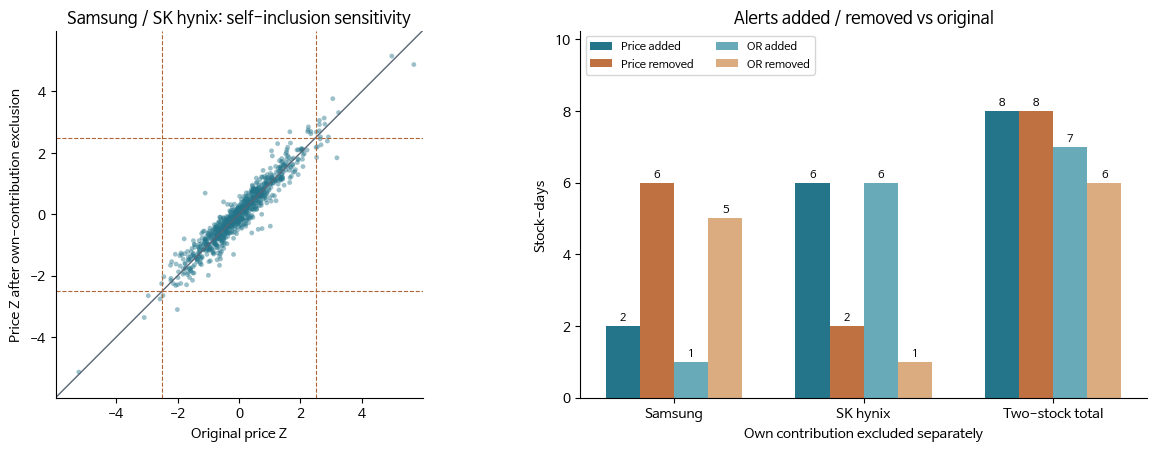

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
m = reference.code.isin(["005930", "000660"])
x, y = reference.loc[m, "price_z"], frames["SELF_EXCLUDED"].loc[m, "price_z"]
axes[0].scatter(x, y, s=12, alpha=.45, color="#24758a", edgecolors="none")
lim = max(3.5, abs(x).max(), abs(y).max()) * 1.05
axes[0].plot([-lim, lim], [-lim, lim], color="#596475", lw=1)
for t in [-CONFIG.price_threshold, CONFIG.price_threshold]:
    axes[0].axvline(t, color="#b06435", ls="--", lw=.8)
    axes[0].axhline(t, color="#b06435", ls="--", lw=.8)
axes[0].set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="Original price Z", ylabel="Price Z after own-contribution exclusion",
            title="Samsung / SK hynix: self-inclusion sensitivity")
axes[0].set_aspect("equal", adjustable="box")
ticks = np.arange(len(main))
for offset, col, label, color in [(-.27, "price_added", "Price added", "#24758a"), (-.09, "price_removed", "Price removed", "#bf7142"),
                                (.09, "or_added", "OR added", "#69aab8"), (.27, "or_removed", "OR removed", "#dbac80")]:
    bars = axes[1].bar(ticks + offset, main[col], width=.18, label=label, color=color)
    axes[1].bar_label(bars, fontsize=8, padding=2)
axes[1].set_xticks(ticks, ["Samsung", "SK hynix", "Two-stock total"])
axes[1].set(xlabel="Own contribution excluded separately", ylabel="Stock-days", title="Alerts added / removed vs original")
axes[1].set_ylim(0, max(1, main[["price_added", "price_removed", "or_added", "or_removed"]].max().max()) * 1.28)
axes[1].legend(ncol=2, fontsize=8, loc="upper left")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 코드 셀 9 · 실험 결과 저장
저장 위치는 **`FDS_regression_model/experiments/3_4_market_sensitivity/`**다. 재실행하면 이 폴더의 실험 출력만 갱신한다. `summary.csv`는 모든 비교 범위, `report_metrics.csv`·`report_alerts.csv`는 두 대형주의 본문용 요약표다. `by_company.csv`, `by_period.csv`, `changed_cases.csv`, `case_examples.csv`는 해석 근거이며, `scenario_results.csv`는 판정 불가를 포함한 네 시나리오 전체 결과다. `legacy_case.csv`의 2024년 사례는 별도 참고용이다. 시가총액·비중·종목별 근사 시장 수익률과 설정·코드 해시도 보관한다.

In [15]:
OUT.mkdir(parents=True, exist_ok=True)
tables = {"summary": summary, "report_metrics": report_metrics, "report_alerts": report_alerts,
    "by_company": by_company, "by_period": by_period, "market_summary": market_summary,
    "coverage": coverage, "excluded_samples": excluded, "changed_cases": changed_cases,
    "case_examples": case_examples, "legacy_case": legacy_case, "all_comparisons": pairs_all,
    "scenario_results": pd.concat([f.reset_index().assign(scenario=s) for s, f in results.items()], ignore_index=True),
    "market_returns": market_returns.reset_index(), "market_diagnostics": market_diag,
    "applied_weights": lag_weights.reset_index(), "market_caps_used": caps.reset_index(),
    "weight_summary": weight_summary.rename_axis("name").reset_index()}
for name, table in tables.items():
    table.to_csv(OUT / f"{name}.csv", index=False, encoding="utf-8-sig")
fig.savefig(OUT / "market_sensitivity.png", dpi=220, facecolor="white")
pkg_version = lambda p: importlib.metadata.version(p)
meta = {"experiment": "3.4 per-stock own-contribution sensitivity (approximation)", "implementation_revision": "self_inclusion_v2",
    "created_at_utc": datetime.now(timezone.utc).isoformat(), "analysis_start": str(START.date()),
    "analysis_end": str(END.date()), "preparation_start": str(sessions.min().date()),
    "model": CONFIG.to_dict(), "input_sha256": input_hashes, "source_run_config_sha256": sha(MODEL_DIR / "run_config.json"),
    "source_code_sha256": {n: sha(MODEL_DIR / "semiconductor_model" / n) for n in ("core.py", "data.py", "config.py", "universe.py")},
    "cap_source": cap_meta, "cap_input_sha256": sha(cap_path), "max_kospi_close_gap_points": float(close_gap.max()),
    "scenarios": SCENARIOS, "weight_lag_trading_days": 1, "preferred_shares_adjusted": False,
    "market_adjustment_scope": "Only each selected stock uses its own-excluded market; other stocks retain original indices",
    "primary_scope": "MEGACAP_2", "legacy_case_excluded_from_main_counts": True, "requested_rows": len(base), "common_rows": int(common.sum()),
    "excluded_rows": int((~common).sum()), "baseline_or_alerts": int((base.price_alert | base.volume_alert).sum()),
    "python": platform.python_version(), "packages": {p: pkg_version(p) for p in ("numpy", "pandas", "matplotlib")},
    "outputs_sha256": {p.name: sha(p) for p in OUT.glob("*.csv")}}
(OUT / "experiment_config.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"저장 완료: {OUT.resolve()}")
print("보고서: report_metrics.csv · report_alerts.csv · by_company.csv · changed_cases.csv · market_sensitivity.png")

저장 완료: C:\ai_campus_mini_proj\FDS_regression_model\experiments\3_4_market_sensitivity
보고서: report_metrics.csv · report_alerts.csv · by_company.csv · changed_cases.csv · market_sensitivity.png


## 결과를 보고 3.4절에 남길 내용

1. **방법:** 기존 기간·설정을 유지하고 두 대형주가 각각 전일 시가총액 비중으로 자신의 기여분만 근사 제외한 시장을 사용했다. 순섹터·종목 회귀·Z를 재계산했다.
2. **전체 변화:** 셀 5의 기대 수익률 차이·Z 변화·가격 경보 겹침률·추가/해제 건수를 기재한다. 삼성전자·SK하이닉스 각각과 두 종목 합계를 설명한다.
3. **집중과 사례:** 셀 6에서 어느 대형주·기간에 변화가 큰지 확인한다. 셀 7에서 주요 사례의 경보가 유지되는지, 새 경보가 단순 경계 통과인지 확인한다. 2024년 초기 사례는 본문 집계와 분리한다.
4. **판단 범위:** 변화가 작으면 관측된 수치 범위에서 기존 지수 사용에 대한 민감도가 작았다고 서술한다. 변화가 크면 시장 구성에 따라 종목 해석이 달라질 수 있음을 한계에 반영한다. 어느 경우든 '정확도 향상'이나 '영향이 전혀 없음'을 자동 결론으로 쓰지 않는다. 이 실험만으로 통계적 동등성을 검정한 것은 아니다.

**자료·API 참고**

- [pykrx 공식 문서: KRX 인증·시가총액·지수 조회](https://github.com/sharebook-kr/pykrx/blob/master/README.md)
- [pykrx 지수·시가총액 조회 구현](https://github.com/sharebook-kr/pykrx/blob/master/pykrx/website/krx/market/wrap.py)
- [KRX 지수 정보](https://index.krx.co.kr/contents/MKD/03/0301/03010000/MKD03010000T4.jsp): 지수 계산 범위와 관련 통계의 포함 범위 차이에 유의한다. 이 노트북은 일별 상장시가총액을 비중의 대용으로 사용한다.